# Olist E-Commerce Analytics
## 03 — Customer Analysis

### Objective

Analyze customer purchasing behavior and geographic distribution.

### Key questions

1. How many unique customers are represented in the dataset?
2. How many orders does each customer place?
3. What proportion of customers are one-time vs repeat customers?
4. Where are customers geographically concentrated?
5. What customer-level metrics can support segmentation?

In [6]:
import pandas as pd
import numpy as np

RAW_PATH = "../02_data/raw/"
PROCESSED_PATH = "../02_data/processed/"

In [7]:
customers = pd.read_csv(
    RAW_PATH + "olist_customers_dataset.csv"
)

orders = pd.read_csv(
    PROCESSED_PATH + "orders_clean.csv"
)

In [8]:
customers.shape

(99441, 5)

In [9]:
orders.shape

(99441, 19)

In [10]:
customers["customer_id"].nunique()

99441

In [11]:
customers["customer_unique_id"].nunique()

96096

In [12]:
customers["customer_id"].duplicated().sum()

np.int64(0)

In [13]:
customer_orders = customers.merge(
    orders,
    on="customer_id",
    how="inner"
)

In [14]:
customer_orders.shape

(99441, 23)

In [15]:
customer_orders["customer_unique_id"].nunique()

96096

In [16]:
orders_per_customer = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

In [17]:
orders_per_customer.head()

,customer_unique_id,order_count
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [18]:
orders_per_customer["order_count"].describe()

count    96096.000000
mean         1.034809
std          0.214384
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         17.000000
Name: order_count, dtype: float64

In [19]:
orders_per_customer["customer_type"] = np.where(
    orders_per_customer["order_count"] == 1,
    "One-time",
    "Repeat"
)

In [20]:
orders_per_customer["customer_type"].value_counts()

customer_type
One-time    93099
Repeat       2997
Name: count, dtype: int64

In [21]:
orders_per_customer["customer_type"].value_counts(
    normalize=True
).mul(100).round(2)

customer_type
One-time    96.88
Repeat       3.12
Name: proportion, dtype: float64

In [22]:
orders_per_customer.sort_values(
    "order_count",
    ascending=False
).head(10)

,customer_unique_id,order_count,customer_type
52973,8d50f5eadf50201ccdcedfb9e2ac8455,17,Repeat
23472,3e43e6105506432c953e165fb2acf44c,9,Repeat
10354,1b6c7548a2a1f9037c1fd3ddfed95f33,7,Repeat
37797,6469f99c1f9dfae7733b25662e7f1782,7,Repeat
76082,ca77025e7201e3b30c44b472ff346268,7,Repeat
27043,47c1a3033b8b77b3ab6e109eb4d5fdf3,6,Repeat
7175,12f5d6e1cbf93dafd9dcc19095df0b3d,6,Repeat
37585,63cfc61cee11cbe306bff5857d00bfe4,6,Repeat
82883,dc813062e0fc23409cd255f7f53c7074,6,Repeat
83540,de34b16117594161a6a89c50b289d35a,6,Repeat


## 2. Customer Monetary Analysis

We now integrate order-level and item-level data to quantify customer purchasing value.

In [23]:
order_items = pd.read_csv(
    RAW_PATH + "olist_order_items_dataset.csv"
)

In [24]:
order_items.shape

(112650, 7)

In [25]:
order_items[
    ["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value"]
].head()

,order_id,order_item_id,product_id,seller_id,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14


In [26]:
order_items["item_total_value"] = (
    order_items["price"] +
    order_items["freight_value"]
)

In [27]:
order_items[
    ["price", "freight_value", "item_total_value"]
].describe()

,price,freight_value,item_total_value
count,112650.000000,112650.000000,112650.000000
mean,120.653739,19.990320,140.644059
std,183.633928,15.806405,190.724394
min,0.850000,0.000000,6.080000
25%,39.900000,13.080000,55.220000
50%,74.990000,16.260000,92.320000
75%,134.900000,21.150000,157.937500
max,6735.000000,409.680000,6929.310000


In [28]:
order_items_orders = order_items.merge(
    orders[
        [
            "order_id",
            "customer_id",
            "order_status",
            "order_purchase_timestamp",
            "purchase_year_month",
            "is_completed"
        ]
    ],
    on="order_id",
    how="left"
)

In [29]:
order_items_orders.shape

(112650, 13)

In [30]:
order_items_orders["customer_id"].isna().sum()

np.int64(0)

In [31]:
customer_orders_items = order_items_orders.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

In [32]:
customer_orders_items.shape

(112650, 14)

In [33]:
customer_orders_items["customer_unique_id"].isna().sum()

np.int64(0)

In [34]:
customer_value = (
    customer_orders_items
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique"),
        item_count=("order_item_id", "count"),
        product_spend=("price", "sum"),
        freight_spend=("freight_value", "sum"),
        total_spend=("item_total_value", "sum")
    )
    .reset_index()
)

In [35]:
customer_value.head()

,customer_unique_id,order_count,item_count,product_spend,freight_spend,total_spend
0,0000366f3b9a7992bf8c76cfdf3221e2,1,1,129.90,12.00,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,1,18.90,8.29,27.19
2,0000f46a3911fa3c0805444483337064,1,1,69.00,17.22,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,1,1,25.99,17.63,43.62
4,0004aac84e0df4da2b147fca70cf8255,1,1,180.00,16.89,196.89


In [36]:
customer_value["avg_order_value"] = (
    customer_value["total_spend"] /
    customer_value["order_count"]
)

In [37]:
customer_value[
    [
        "order_count",
        "item_count",
        "product_spend",
        "freight_spend",
        "total_spend",
        "avg_order_value"
    ]
].describe()

,order_count,item_count,product_spend,freight_spend,total_spend,avg_order_value
count,95420.000000,95420.00000,95420.000000,95420.000000,95420.000000,95420.000000
mean,1.034018,1.18057,142.440198,23.599974,166.040172,161.044770
std,0.211234,0.62145,217.656355,22.878663,228.320333,221.191784
min,1.000000,1.00000,0.850000,0.000000,9.590000,9.590000
25%,1.000000,1.00000,47.900000,14.080000,63.100000,62.410000
50%,1.000000,1.00000,89.900000,17.600000,107.940000,105.770000
75%,1.000000,1.00000,155.000000,25.540000,183.220000,177.122500
max,16.000000,24.00000,13440.000000,1794.960000,13664.080000,13664.080000


In [38]:
customer_value.shape

(95420, 7)

In [39]:
customer_value["customer_unique_id"].nunique()

95420

In [40]:
unique_customers = customers["customer_unique_id"].nunique()

customers_with_items = (
    customer_value["customer_unique_id"].nunique()
)

print("Total unique customers:", unique_customers)
print("Customers with item records:", customers_with_items)
print(
    "Customers without item records:",
    unique_customers - customers_with_items
)

Total unique customers: 96096
Customers with item records: 95420
Customers without item records: 676


In [41]:
customer_value.sort_values(
    "total_spend",
    ascending=False
).head(10)

,customer_unique_id,order_count,item_count,product_spend,freight_spend,total_spend,avg_order_value
3799,0a0a92112bd4c708ca5fde585afaa872,1,8,13440.0,224.08,13664.08,13664.080
81388,da122df9eeddfedc1dc1f5349a1a690c,2,2,7388.0,183.63,7571.63,3785.815
44139,763c8b1c9c68a0229c42c9fc6f662b93,1,4,7160.0,114.88,7274.88,7274.880
82230,dc4802a71eae9be1dd28f5d788ceb526,1,1,6735.0,194.31,6929.31,6929.310
26015,459bef486812aa25204be022145caa62,1,1,6729.0,193.21,6922.21,6922.210
95131,ff4159b92c40ebe40454e3e6a7c35ed6,1,1,6499.0,227.66,6726.66,6726.660
23947,4007669dec559734d6f53e029e360987,1,6,5934.6,146.94,6081.54,6081.540
34820,5d0a2980b292d049061542014e8960bf,1,2,4599.9,209.54,4809.44,4809.440
89056,eebb5dda148d3893cdaf5b5ca3040ccb,1,1,4690.0,74.34,4764.34,4764.340
27242,48e1ac109decbb87765a3eade6854098,1,1,4590.0,91.78,4681.78,4681.780


In [42]:
customers_without_items = customers[
    ~customers["customer_unique_id"].isin(
        customer_value["customer_unique_id"]
    )
]

customers_without_items.shape

(685, 5)

In [43]:
customers_without_items_orders = customers_without_items.merge(
    orders[
        [
            "order_id",
            "customer_id",
            "order_status",
            "order_purchase_timestamp"
        ]
    ],
    on="customer_id",
    how="left"
)

In [44]:
customers_without_items_orders["order_status"].value_counts()

order_status
unavailable    569
canceled       109
created          4
invoiced         2
shipped          1
Name: count, dtype: int64

In [45]:
customers_without_items_orders.groupby(
    "customer_unique_id"
)["order_id"].nunique().describe()

count    676.000000
mean       1.013314
std        0.126960
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        3.000000
Name: order_id, dtype: float64

In [46]:
customers_without_items_orders[
    customers_without_items_orders["order_status"] == "delivered"
].shape

(0, 8)

## 3. RFM Customer Analysis

RFM analysis will be based on completed (delivered) orders to ensure that
customer value reflects realized purchases rather than cancelled or
unavailable transactions.

In [47]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

In [48]:
delivered_orders.shape

(96478, 19)

In [49]:
delivered_orders["customer_id"].nunique()

96478

In [50]:
delivered_orders = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

In [51]:
delivered_orders["customer_unique_id"].isna().sum()

np.int64(0)

In [52]:
delivered_items = order_items_orders[
    order_items_orders["order_status"] == "delivered"
].copy()

In [53]:
delivered_items.shape

(110197, 13)

In [54]:
delivered_items["order_id"].nunique()

96478

In [55]:
customer_monetary = (
    delivered_items
    .groupby("customer_id")
    .agg(
        product_spend=("price", "sum"),
        freight_spend=("freight_value", "sum"),
        total_spend=("item_total_value", "sum")
    )
    .reset_index()
)

In [56]:
customer_monetary = customer_monetary.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

In [57]:
customer_frequency = (
    delivered_orders
    .groupby("customer_unique_id")
    .agg(
        frequency=("order_id", "nunique")
    )
    .reset_index()
)

In [58]:
customer_frequency["frequency"].describe()

count    93358.000000
mean         1.033420
std          0.209097
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         15.000000
Name: frequency, dtype: float64

In [59]:
delivered_orders["order_purchase_timestamp"] = pd.to_datetime(
    delivered_orders["order_purchase_timestamp"]
)

reference_date = (
    delivered_orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

reference_date

Timestamp('2018-08-30 15:00:37')

In [60]:
customer_recency = (
    delivered_orders
    .groupby("customer_unique_id")
    .agg(
        last_purchase_date=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

In [61]:
customer_recency["recency_days"] = (
    reference_date -
    customer_recency["last_purchase_date"]
).dt.days

In [62]:
customer_recency["recency_days"].describe()

count    93358.000000
mean       237.941773
std        152.591453
min          1.000000
25%        114.000000
50%        219.000000
75%        346.000000
max        714.000000
Name: recency_days, dtype: float64

In [63]:
rfm = customer_recency.merge(
    customer_frequency,
    on="customer_unique_id",
    how="inner"
).merge(
    customer_monetary[
        [
            "customer_unique_id",
            "product_spend",
            "freight_spend",
            "total_spend"
        ]
    ],
    on="customer_unique_id",
    how="inner"
)

In [64]:
rfm.shape

(96478, 7)

In [65]:
rfm.head()

,customer_unique_id,last_purchase_date,recency_days,frequency,product_spend,freight_spend,total_spend
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,112,1,129.90,12.00,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,115,1,18.90,8.29,27.19
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,537,1,69.00,17.22,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,321,1,25.99,17.63,43.62
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,288,1,180.00,16.89,196.89


In [66]:
rfm["avg_order_value"] = (
    rfm["total_spend"] /
    rfm["frequency"]
)

In [67]:
rfm[
    [
        "recency_days",
        "frequency",
        "product_spend",
        "freight_spend",
        "total_spend",
        "avg_order_value"
    ]
].describe()

,recency_days,frequency,product_spend,freight_spend,total_spend,avg_order_value
count,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000
mean,237.255188,1.075727,137.041586,22.785253,159.826839,155.103932
std,152.384623,0.374276,209.045198,21.559197,218.794219,216.651917
min,1.000000,1.000000,0.850000,0.000000,9.590000,1.451333
25%,114.000000,1.000000,45.900000,13.850000,61.850000,58.220000
50%,218.000000,1.000000,86.575000,17.170000,105.280000,101.130000
75%,345.000000,1.000000,149.900000,24.017500,176.260000,171.817500
max,714.000000,15.000000,13440.000000,1794.960000,13664.080000,13664.080000


In [68]:
(rfm["recency_days"] < 0).sum()

np.int64(0)

In [69]:
(rfm["frequency"] <= 0).sum()

np.int64(0)

In [70]:
(rfm["total_spend"] < 0).sum()

np.int64(0)

In [71]:
rfm.isna().sum()

customer_unique_id    0
last_purchase_date    0
recency_days          0
frequency             0
product_spend         0
freight_spend         0
total_spend           0
avg_order_value       0
dtype: int64

In [72]:
rfm["frequency"].value_counts().sort_index()

frequency
1     90557
2      5146
3       543
4       112
5        45
6        30
7        21
9         9
15       15
Name: count, dtype: int64

In [73]:
rfm["total_spend"].describe()

count    96478.000000
mean       159.826839
std        218.794219
min          9.590000
25%         61.850000
50%        105.280000
75%        176.260000
max      13664.080000
Name: total_spend, dtype: float64

In [74]:
rfm["recency_days"].describe()

count    96478.000000
mean       237.255188
std        152.384623
min          1.000000
25%        114.000000
50%        218.000000
75%        345.000000
max        714.000000
Name: recency_days, dtype: float64

In [75]:
rfm["R_score"] = pd.qcut(
    rfm["recency_days"],
    q=5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

In [76]:
rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
)

In [77]:
rfm["M_score"] = pd.qcut(
    rfm["total_spend"],
    q=5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

In [78]:
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

In [79]:
rfm[
    [
        "customer_unique_id",
        "recency_days",
        "frequency",
        "total_spend",
        "R_score",
        "F_score",
        "M_score"
    ]
].head(10)

,customer_unique_id,recency_days,frequency,total_spend,R_score,F_score,M_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,3
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98,4,1,4
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38,4,1,1
7,00053a61a98854899e70ed204dd4bafe,183,1,419.18,3,1,5
8,0005e1862207bf6ccc02e4228effd9a0,543,1,150.12,1,1,4
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,129.76,4,1,4


In [80]:
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

In [81]:
rfm.sort_values(
    ["R_score", "F_score", "M_score"],
    ascending=False
).head(20)

,customer_unique_id,last_purchase_date,recency_days,frequency,product_spend,freight_spend,total_spend,avg_order_value,R_score,F_score,M_score,RFM_score
445,012a218df8995d3ec3bb221828360c86,2018-06-18 13:08:38,73,2,1369.90,66.07,1435.97,717.985,5,5,5,555
739,01f2285f85a1c603eb7ef755ad311769,2018-05-31 14:51:03,91,2,252.00,19.64,271.64,135.820,5,5,5,555
1201,032b3a42598667caf2e099999b9dc1b9,2018-07-24 21:17:34,36,2,259.90,62.80,322.70,161.350,5,5,5,555
1280,0361e980b28826f4d286ac144d9b319a,2018-07-01 18:03:34,59,2,234.00,124.59,358.59,179.295,5,5,5,555
2106,059e7585d8fcd2430a33375bdbcbb990,2018-08-19 12:03:34,11,2,401.70,50.89,452.59,226.295,5,5,5,555
2639,070acf4df1234a6257809e4e79644481,2018-07-18 07:41:58,43,2,204.00,116.58,320.58,160.290,5,5,5,555
2640,070acf4df1234a6257809e4e79644481,2018-07-18 07:41:58,43,2,669.99,20.45,690.44,345.220,5,5,5,555
3020,07ff81a9676efa0286ddd3f09e7c0063,2018-06-11 17:56:07,79,2,160.44,75.60,236.04,118.020,5,5,5,555
3021,07ff81a9676efa0286ddd3f09e7c0063,2018-06-11 17:56:07,79,2,160.44,87.84,248.28,124.140,5,5,5,555
4612,0c1201c04330536234aaa49b396745d4,2018-08-05 07:57:13,25,2,196.80,58.90,255.70,127.850,5,5,5,555


In [82]:
rfm.sort_values(
    "total_spend",
    ascending=False
).head(10)

,customer_unique_id,last_purchase_date,recency_days,frequency,product_spend,freight_spend,total_spend,avg_order_value,R_score,F_score,M_score,RFM_score
3835,0a0a92112bd4c708ca5fde585afaa872,2017-09-29 15:24:52,334,1,13440.00,224.08,13664.08,13664.08,2,1,5,215
44601,763c8b1c9c68a0229c42c9fc6f662b93,2018-07-15 14:49:44,46,1,7160.00,114.88,7274.88,7274.88,5,3,5,535
83160,dc4802a71eae9be1dd28f5d788ceb526,2017-02-12 20:37:36,563,1,6735.00,194.31,6929.31,6929.31,1,5,5,155
26249,459bef486812aa25204be022145caa62,2018-07-25 18:10:17,35,1,6729.00,193.21,6922.21,6922.21,5,2,5,525
96196,ff4159b92c40ebe40454e3e6a7c35ed6,2017-05-24 18:14:34,462,1,6499.00,227.66,6726.66,6726.66,1,5,5,155
24168,4007669dec559734d6f53e029e360987,2017-11-24 11:03:35,279,1,5934.60,146.94,6081.54,6081.54,2,2,5,225
82306,da122df9eeddfedc1dc1f5349a1a690c,2017-04-01 15:58:41,515,2,4799.00,151.34,4950.34,2475.17,1,5,5,155
90087,eebb5dda148d3893cdaf5b5ca3040ccb,2017-04-18 18:50:13,498,1,4690.00,74.34,4764.34,4764.34,1,5,5,155
27493,48e1ac109decbb87765a3eade6854098,2018-06-22 12:23:19,69,1,4590.00,91.78,4681.78,4681.78,5,2,5,525
89787,edde2314c6c30e864a128ac95d6b2112,2018-08-03 21:10:16,26,1,4399.87,113.45,4513.32,4513.32,5,5,5,555


In [83]:
rfm.shape

(96478, 12)

In [84]:
rfm.columns.tolist()

['customer_unique_id',
 'last_purchase_date',
 'recency_days',
 'frequency',
 'product_spend',
 'freight_spend',
 'total_spend',
 'avg_order_value',
 'R_score',
 'F_score',
 'M_score',
 'RFM_score']

In [85]:
rfm["customer_unique_id"].nunique()

93358

In [86]:
rfm["customer_unique_id"].duplicated().sum()

np.int64(3120)

In [87]:
delivered_items.columns.tolist()

['order_id',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'item_total_value',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'purchase_year_month',
 'is_completed']

In [88]:
delivered_items = delivered_items.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

In [89]:
delivered_items["customer_unique_id"].isna().sum()

np.int64(0)

In [90]:
customer_monetary = (
    delivered_items
    .groupby("customer_unique_id")
    .agg(
        product_spend=("price", "sum"),
        freight_spend=("freight_value", "sum"),
        total_spend=("item_total_value", "sum")
    )
    .reset_index()
)

In [91]:
customer_monetary.shape

(93358, 4)

In [92]:
customer_monetary["customer_unique_id"].nunique()

93358

In [93]:
customer_monetary["customer_unique_id"].duplicated().sum()

np.int64(0)

In [94]:
rfm = (
    customer_recency
    .merge(
        customer_frequency,
        on="customer_unique_id",
        how="inner"
    )
    .merge(
        customer_monetary,
        on="customer_unique_id",
        how="inner"
    )
)

In [95]:
rfm.shape

(93358, 7)

In [96]:
rfm["customer_unique_id"].nunique()

93358

In [97]:
rfm["customer_unique_id"].duplicated().sum()

np.int64(0)

In [98]:
rfm["avg_order_value"] = (
    rfm["total_spend"] / rfm["frequency"]
)

In [99]:
rfm.isna().sum()

customer_unique_id    0
last_purchase_date    0
recency_days          0
frequency             0
product_spend         0
freight_spend         0
total_spend           0
avg_order_value       0
dtype: int64

In [100]:
rfm = rfm.drop(
    columns=["R_score", "F_score", "M_score", "RFM_score"],
    errors="ignore"
)

In [101]:
rfm.columns.tolist()

['customer_unique_id',
 'last_purchase_date',
 'recency_days',
 'frequency',
 'product_spend',
 'freight_spend',
 'total_spend',
 'avg_order_value']

In [102]:
print("RFM shape:", rfm.shape)
print("Unique customers:", rfm["customer_unique_id"].nunique())
print("Duplicate IDs:", rfm["customer_unique_id"].duplicated().sum())

RFM shape: (93358, 8)
Unique customers: 93358
Duplicate IDs: 0


In [103]:
rfm.isna().sum()

customer_unique_id    0
last_purchase_date    0
recency_days          0
frequency             0
product_spend         0
freight_spend         0
total_spend           0
avg_order_value       0
dtype: int64

In [104]:
rfm["recency_days"].describe()

count    93358.000000
mean       237.941773
std        152.591453
min          1.000000
25%        114.000000
50%        219.000000
75%        346.000000
max        714.000000
Name: recency_days, dtype: float64

In [105]:
rfm["frequency"].value_counts().sort_index()

frequency
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [106]:
rfm["total_spend"].describe()

count    93358.000000
mean       165.168210
std        226.292101
min          9.590000
25%         63.010000
50%        107.780000
75%        182.510000
max      13664.080000
Name: total_spend, dtype: float64

In [107]:
rfm["R_score"] = pd.qcut(
    rfm["recency_days"],
    q=5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

In [108]:
rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
)

In [109]:
rfm["M_score"] = pd.qcut(
    rfm["total_spend"],
    q=5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

In [110]:
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

In [111]:
rfm[
    [
        "customer_unique_id",
        "recency_days",
        "frequency",
        "total_spend",
        "R_score",
        "F_score",
        "M_score"
    ]
].head(10)

,customer_unique_id,recency_days,frequency,total_spend,R_score,F_score,M_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98,4,1,4
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38,4,1,1
7,00053a61a98854899e70ed204dd4bafe,183,1,419.18,3,1,5
8,0005e1862207bf6ccc02e4228effd9a0,543,1,150.12,1,1,4
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,129.76,4,1,3


In [112]:
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

In [113]:
rfm[
    ["R_score", "F_score", "M_score"]
].describe()

,R_score,F_score,M_score
count,93358.000000,93358.000000,93358.000000
mean,3.003278,3.000000,2.999936
std,1.414346,1.414229,1.414282
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,2.000000
50%,3.000000,3.000000,3.000000
75%,4.000000,4.000000,4.000000
max,5.000000,5.000000,5.000000


In [114]:
rfm["RFM_score"].nunique()

125

In [115]:
rfm["RFM_score"].value_counts().head(20)

RFM_score
555    1000
455     959
255     897
355     889
222     859
155     851
242     843
424     839
531     833
131     827
331     824
344     817
454     816
121     806
112     806
132     805
142     805
544     802
341     800
111     799
Name: count, dtype: int64

In [116]:
rfm.groupby("RFM_score").agg(
    customers=("customer_unique_id", "count"),
    avg_recency=("recency_days", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_spend=("total_spend", "mean")
).sort_values(
    "customers",
    ascending=False
).head(20)

,customers,avg_recency,avg_frequency,avg_spend
RFM_score,,,,
555,1000,46.423000,1.457000,450.305890
455,959,134.807091,1.419187,454.598071
255,897,316.336678,1.358974,436.596254
355,889,219.520810,1.434196,417.086108
222,859,317.251455,1.000000,70.237614
155,851,474.642773,1.270270,458.950458
242,843,316.326216,1.000000,70.635409
424,839,135.511323,1.000000,166.997855
531,833,46.159664,1.000000,40.078079


In [117]:
rfm["F_score"] = np.select(
    [
        rfm["frequency"] == 1,
        rfm["frequency"] == 2,
        rfm["frequency"] == 3,
        rfm["frequency"].isin([4, 5]),
        rfm["frequency"] >= 6
    ],
    [1, 2, 3, 4, 5],
    default=np.nan
)

In [118]:
rfm["F_score"] = rfm["F_score"].astype(int)

In [119]:
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

In [120]:
rfm[
    ["R_score", "F_score", "M_score"]
].describe()

,R_score,F_score,M_score
count,93358.000000,93358.000000,93358.000000
mean,3.003278,1.033056,2.999936
std,1.414346,0.198757,1.414282
min,1.000000,1.000000,1.000000
25%,2.000000,1.000000,2.000000
50%,3.000000,1.000000,3.000000
75%,4.000000,1.000000,4.000000
max,5.000000,5.000000,5.000000


In [121]:
rfm["F_score"].value_counts().sort_index()

F_score
1    90557
2     2573
3      181
4       37
5       10
Name: count, dtype: int64

In [122]:
rfm["RFM_score"].nunique()

78

In [123]:
rfm["customer_segment"] = np.select(
    [
        (rfm["R_score"] >= 4) &
        (rfm["F_score"] >= 4) &
        (rfm["M_score"] >= 4),

        (rfm["F_score"] >= 4) &
        (rfm["M_score"] >= 3),

        (rfm["R_score"] >= 4) &
        (rfm["F_score"] <= 3),

        (rfm["R_score"] <= 2) &
        (rfm["F_score"] >= 3) &
        (rfm["M_score"] >= 3),

        (rfm["R_score"] <= 2) &
        (rfm["F_score"] <= 2) &
        (rfm["M_score"] <= 2)
    ],
    [
        "Champions",
        "Loyal Customers",
        "Potential Loyalists",
        "At Risk",
        "Hibernating / Low Value"
    ],
    default="Other"
)

In [124]:
rfm["customer_segment"].value_counts()

customer_segment
Other                      40478
Potential Loyalists        37400
Hibernating / Low Value    15375
At Risk                       59
Champions                     33
Loyal Customers               13
Name: count, dtype: int64

In [125]:
rfm.to_csv(
    "../07_powerbi/customer_rfm.csv",
    index=False
)

print("Saved successfully.")
print(rfm.shape)
print(rfm.columns.tolist())

Saved successfully.
(93358, 13)
['customer_unique_id', 'last_purchase_date', 'recency_days', 'frequency', 'product_spend', 'freight_spend', 'total_spend', 'avg_order_value', 'R_score', 'F_score', 'M_score', 'RFM_score', 'customer_segment']


In [126]:
segment_analysis = (
    rfm
    .groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "count"),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_spend=("total_spend", "mean"),
        total_revenue=("total_spend", "sum")
    )
    .sort_values(
        "total_revenue",
        ascending=False
    )
)

segment_analysis

,customers,avg_recency,avg_frequency,avg_spend,total_revenue
customer_segment,,,,,
Other,40478,313.756856,1.036464,202.230052,8185868.03
Potential Loyalists,37400,90.578556,1.033824,168.814180,6313650.34
Hibernating / Low Value,15375,396.517593,1.005138,55.788388,857746.46
Champions,33,85.969697,4.939394,864.672727,28534.20
At Risk,59,379.508475,3.000000,432.889153,25540.46
Loyal Customers,13,322.615385,5.000000,648.789231,8434.26


In [127]:
segment_analysis["customer_share_pct"] = (
    segment_analysis["customers"]
    / segment_analysis["customers"].sum()
    * 100
)

In [128]:
segment_analysis["revenue_share_pct"] = (
    segment_analysis["total_revenue"]
    / segment_analysis["total_revenue"].sum()
    * 100
)

In [129]:
segment_analysis

,customers,avg_recency,avg_frequency,avg_spend,total_revenue,customer_share_pct,revenue_share_pct
customer_segment,,,,,,,
Other,40478,313.756856,1.036464,202.230052,8185868.03,43.357827,53.086823
Potential Loyalists,37400,90.578556,1.033824,168.814180,6313650.34,40.060841,40.945156
Hibernating / Low Value,15375,396.517593,1.005138,55.788388,857746.46,16.468862,5.562640
Champions,33,85.969697,4.939394,864.672727,28534.20,0.035348,0.185049
At Risk,59,379.508475,3.000000,432.889153,25540.46,0.063198,0.165634
Loyal Customers,13,322.615385,5.000000,648.789231,8434.26,0.013925,0.054698


In [130]:
rfm["F_score"].value_counts().sort_index()

F_score
1    90557
2     2573
3      181
4       37
5       10
Name: count, dtype: int64

In [131]:
rfm["RFM_score"].nunique()

78

In [132]:
segment_analysis = (
    rfm
    .groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "count"),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_spend=("total_spend", "mean"),
        total_revenue=("total_spend", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

segment_analysis["customer_share_pct"] = (
    segment_analysis["customers"]
    / segment_analysis["customers"].sum()
    * 100
)

segment_analysis["revenue_share_pct"] = (
    segment_analysis["total_revenue"]
    / segment_analysis["total_revenue"].sum()
    * 100
)

segment_analysis

,customers,avg_recency,avg_frequency,avg_spend,total_revenue,customer_share_pct,revenue_share_pct
customer_segment,,,,,,,
Other,40478,313.756856,1.036464,202.230052,8185868.03,43.357827,53.086823
Potential Loyalists,37400,90.578556,1.033824,168.814180,6313650.34,40.060841,40.945156
Hibernating / Low Value,15375,396.517593,1.005138,55.788388,857746.46,16.468862,5.562640
Champions,33,85.969697,4.939394,864.672727,28534.20,0.035348,0.185049
At Risk,59,379.508475,3.000000,432.889153,25540.46,0.063198,0.165634
Loyal Customers,13,322.615385,5.000000,648.789231,8434.26,0.013925,0.054698


# 6.15 Customer Segmentation Analysis

## Objective

Analyze customer behavioral segments using RFM scores and identify
customer retention, value concentration, and revenue opportunities.

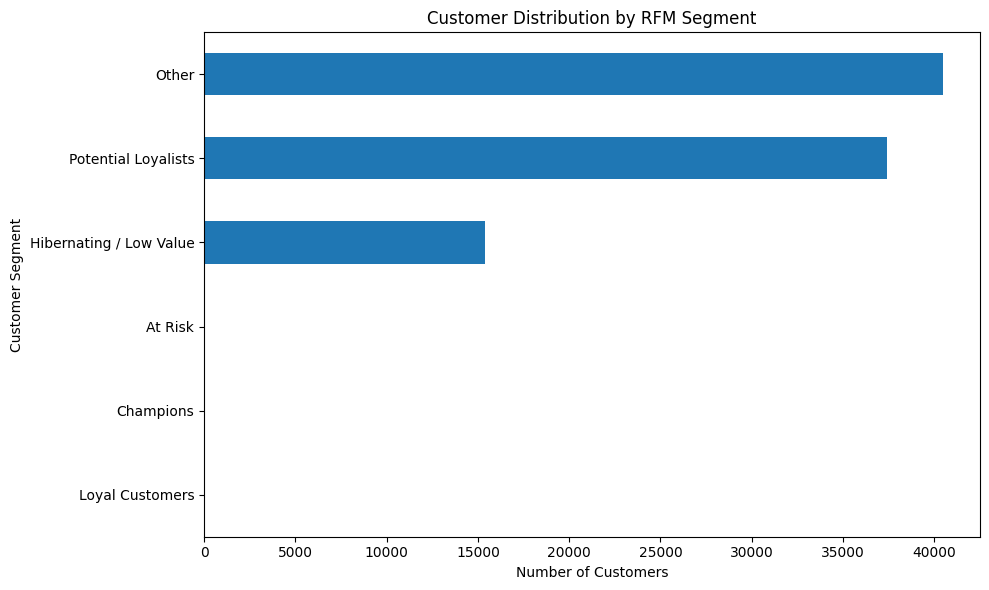

In [133]:
import matplotlib.pyplot as plt

segment_counts = (
    rfm["customer_segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

segment_counts.plot(kind="barh")

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

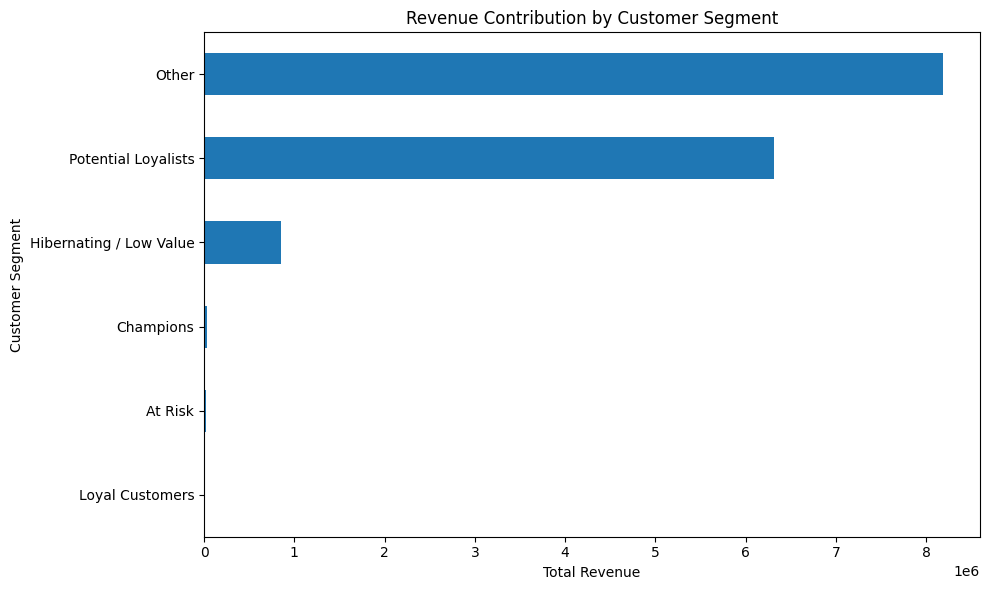

In [134]:
segment_revenue = (
    rfm.groupby("customer_segment")["total_spend"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

segment_revenue.plot(kind="barh")

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

In [135]:
customer_share = (
    rfm["customer_segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

customer_share

customer_segment
Other                      43.36
Potential Loyalists        40.06
Hibernating / Low Value    16.47
At Risk                     0.06
Champions                   0.04
Loyal Customers             0.01
Name: proportion, dtype: float64

In [136]:
revenue_share = (
    rfm.groupby("customer_segment")["total_spend"]
    .sum()
    .div(rfm["total_spend"].sum())
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

revenue_share

customer_segment
Other                      53.09
Potential Loyalists        40.95
Hibernating / Low Value     5.56
Champions                   0.19
At Risk                     0.17
Loyal Customers             0.05
Name: total_spend, dtype: float64

## 6.16 Investigating the "Other" Segment

The "Other" segment represents customers who do not satisfy the
predefined RFM segment rules. Because it contains a substantial
share of both customers and revenue, its internal composition
must be investigated before drawing business conclusions.

In [137]:
other_analysis = (
    rfm[rfm["customer_segment"] == "Other"]
    .groupby(["R_score", "F_score", "M_score"])
    .agg(
        customers=("customer_unique_id", "count"),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_spend=("total_spend", "mean"),
        total_revenue=("total_spend", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

other_analysis

customers  avg_recency  avg_frequency   avg_spend  \
R_score F_score M_score                                                      
2       1       5             3471   316.017862            1.0  453.102947   
1       1       5             3498   476.897656            1.0  441.453679   
3       1       5             3220   220.540373            1.0  410.973354   
                4             3695   220.514479            1.0  165.148022   
2       1       4             3476   315.299194            1.0  164.850814   
1       1       4             3290   471.990881            1.0  163.783061   
                3             3629   472.276660            1.0  109.166575   
3       1       3             3659   221.724788            1.0  108.181637   
2       1       3             3568   316.838004            1.0  108.434084   
3       1       2             3624   220.570640            1.0   70.349407   
                1             3907   219.036857            1.0   39.545733   
        2       5              311   217.935691            2.0  419.550482   
2       2       5              256   318.328125            2.0  421.214727   
1       2       5              199   462.271357            2.0  450.711055   
3       2       4              153   216.477124            2.0  172.487190   
2       2       4              131   315.946565            2.0  168.493511   
1       2       4              104   462.375000            2.0  168.563750   
3       3       5               23   223.391304            3.0  543.094348   
2       2       3               89   313.112360            2.0  113.556180   
3       2       3               77   221.818182            2.0  111.011818   
1       2       3               61   454.590164            2.0  110.673770   
3       2       2               24   214.000000            2.0   75.142500   
        3       4                6   197.833333            3.0  165.826667   
                3                2   211.500000            3.0  106.965000   
        2       1                2   190.500000            2.0   44.930000   
1       4       2                1   602.000000            4.0   73.480000   
        3       2                1   602.000000            3.0   56.860000   
                1                1   602.000000            3.0   46.860000   

                         total_revenue  
R_score F_score M_score                 
2       1       5           1572720.33  
1       1       5           1544204.97  
3       1       5           1323334.20  
                4            610221.94  
2       1       4            573021.43  
1       1       4            538846.27  
                3            396165.50  
3       1       3            395836.61  
2       1       3            386892.81  
3       1       2            254946.25  
                1            154505.18  
        2       5            130480.20  
2       2       5            107830.97  
1       2       5             89691.50  
3       2       4             26390.54  
2       2       4             22072.65  
1       2       4             17530.63  
3       3       5             12491.17  
2       2       3             10106.50  
3       2       3              8547.91  
1       2       3              6751.10  
3       2       2              1803.42  
        3       4               994.96  
                3               213.93  
        2       1                89.86  
1       4       2                73.48  
        3       2                56.86  
                1                46.86

In [138]:
other_analysis.head(15)

customers  avg_recency  avg_frequency   avg_spend  \
R_score F_score M_score                                                      
2       1       5             3471   316.017862            1.0  453.102947   
1       1       5             3498   476.897656            1.0  441.453679   
3       1       5             3220   220.540373            1.0  410.973354   
                4             3695   220.514479            1.0  165.148022   
2       1       4             3476   315.299194            1.0  164.850814   
1       1       4             3290   471.990881            1.0  163.783061   
                3             3629   472.276660            1.0  109.166575   
3       1       3             3659   221.724788            1.0  108.181637   
2       1       3             3568   316.838004            1.0  108.434084   
3       1       2             3624   220.570640            1.0   70.349407   
                1             3907   219.036857            1.0   39.545733   
        2       5              311   217.935691            2.0  419.550482   
2       2       5              256   318.328125            2.0  421.214727   
1       2       5              199   462.271357            2.0  450.711055   
3       2       4              153   216.477124            2.0  172.487190   

                         total_revenue  
R_score F_score M_score                 
2       1       5           1572720.33  
1       1       5           1544204.97  
3       1       5           1323334.20  
                4            610221.94  
2       1       4            573021.43  
1       1       4            538846.27  
                3            396165.50  
3       1       3            395836.61  
2       1       3            386892.81  
3       1       2            254946.25  
                1            154505.18  
        2       5            130480.20  
2       2       5            107830.97  
1       2       5             89691.50  
3       2       4             26390.54

In [139]:
segment_value = (
    rfm.groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "count"),
        total_revenue=("total_spend", "sum")
    )
)

segment_value["revenue_per_customer"] = (
    segment_value["total_revenue"]
    / segment_value["customers"]
)

segment_value.sort_values(
    "revenue_per_customer",
    ascending=False
)

,customers,total_revenue,revenue_per_customer
customer_segment,,,
Champions,33,28534.20,864.672727
Loyal Customers,13,8434.26,648.789231
At Risk,59,25540.46,432.889153
Other,40478,8185868.03,202.230052
Potential Loyalists,37400,6313650.34,168.814180
Hibernating / Low Value,15375,857746.46,55.788388


In [140]:
overall_avg_customer_value = rfm["total_spend"].mean()

overall_avg_customer_value

np.float64(165.1682100087834)

In [141]:
segment_value["index_vs_average"] = (
    segment_value["revenue_per_customer"]
    / overall_avg_customer_value
)

segment_value.sort_values(
    "index_vs_average",
    ascending=False
)

,customers,total_revenue,revenue_per_customer,index_vs_average
customer_segment,,,,
Champions,33,28534.20,864.672727,5.235104
Loyal Customers,13,8434.26,648.789231,3.928051
At Risk,59,25540.46,432.889153,2.620899
Other,40478,8185868.03,202.230052,1.224388
Potential Loyalists,37400,6313650.34,168.814180,1.022074
Hibernating / Low Value,15375,857746.46,55.788388,0.337767


# 6.17 Customer Segment Visualization

This section visualizes customer distribution and revenue contribution
across RFM-based customer segments to identify concentration,
high-value groups, and retention opportunities.

In [142]:
rfm.shape

(93358, 13)

In [143]:
rfm["customer_segment"].value_counts()

customer_segment
Other                      40478
Potential Loyalists        37400
Hibernating / Low Value    15375
At Risk                       59
Champions                     33
Loyal Customers               13
Name: count, dtype: int64

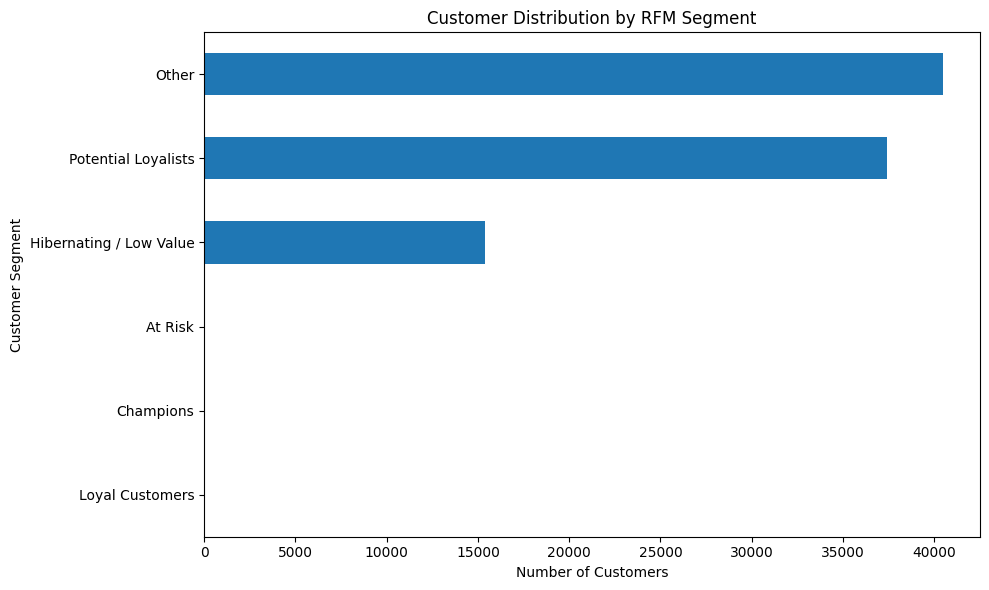

In [144]:
segment_counts = (
    rfm["customer_segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

segment_counts.plot(kind="barh")

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

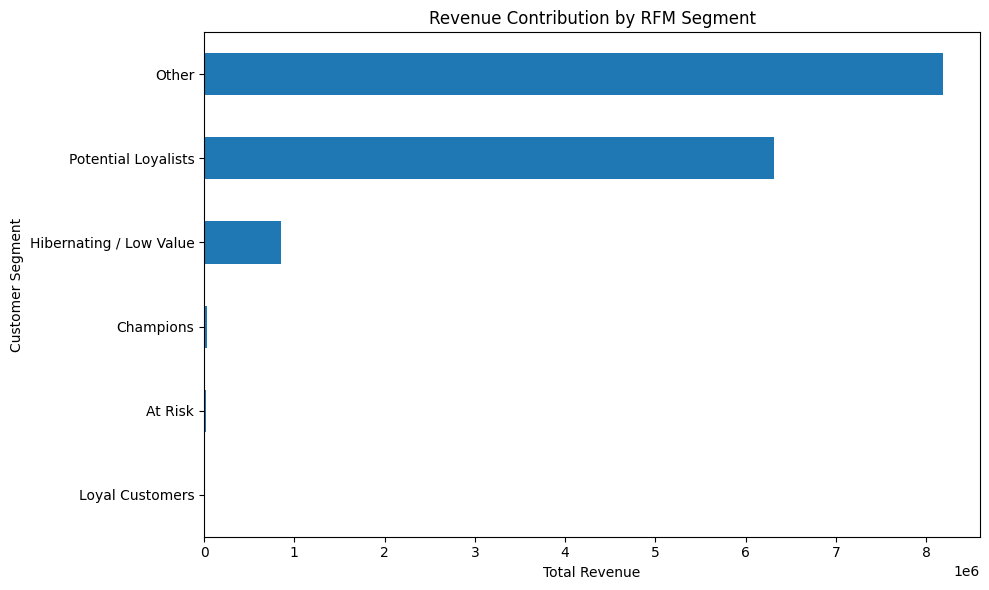

In [145]:
segment_revenue = (
    rfm.groupby("customer_segment")["total_spend"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

segment_revenue.plot(kind="barh")

plt.title("Revenue Contribution by RFM Segment")
plt.xlabel("Total Revenue")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

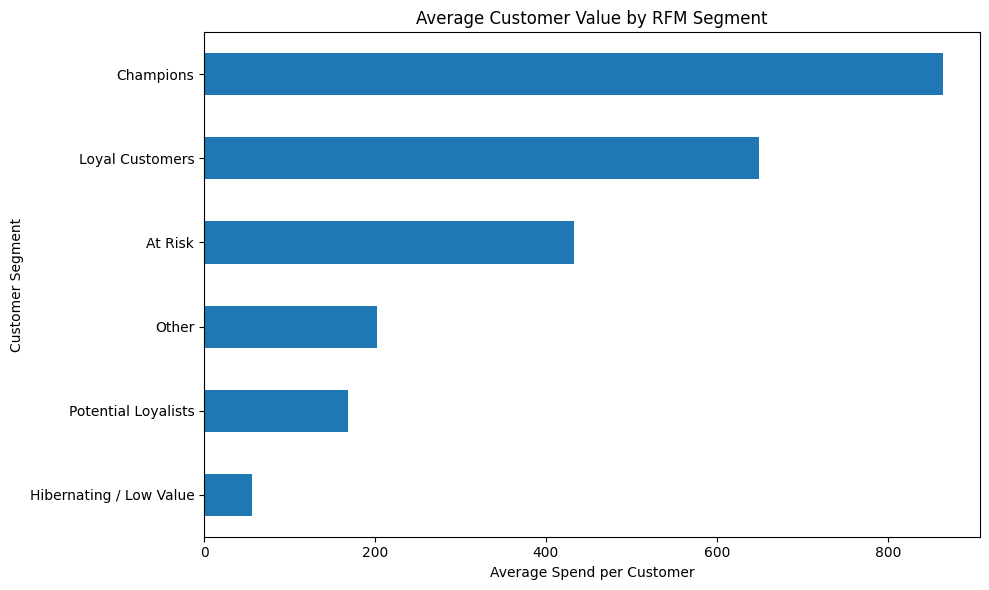

In [146]:
revenue_per_customer = (
    rfm.groupby("customer_segment")["total_spend"]
    .mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

revenue_per_customer.plot(kind="barh")

plt.title("Average Customer Value by RFM Segment")
plt.xlabel("Average Spend per Customer")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

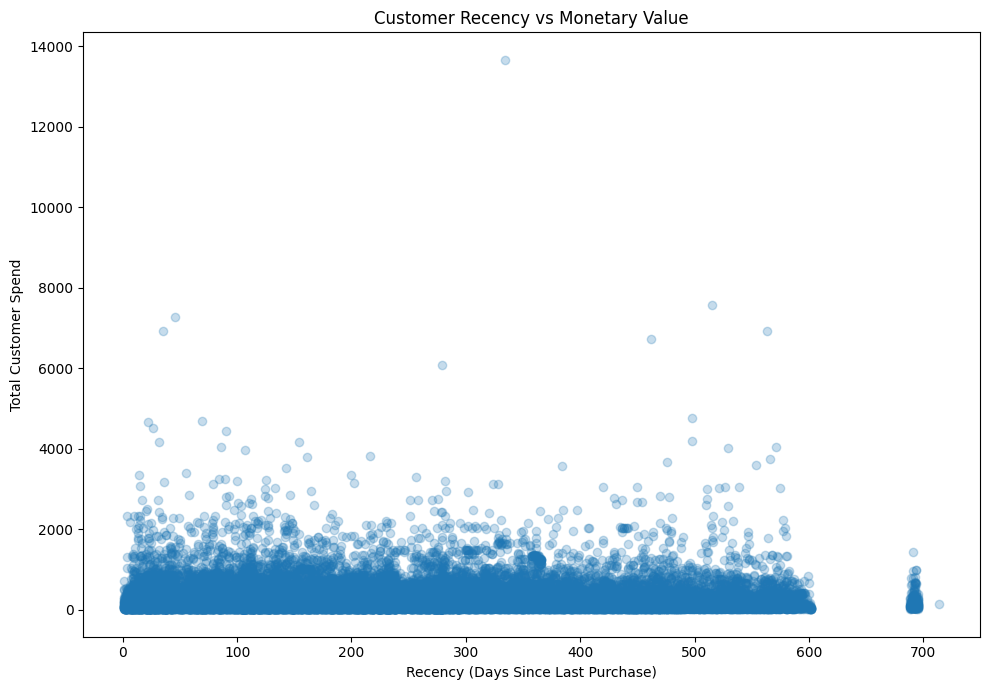

In [147]:
plt.figure(figsize=(10, 7))

plt.scatter(
    rfm["recency_days"],
    rfm["total_spend"],
    alpha=0.25
)

plt.title("Customer Recency vs Monetary Value")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Customer Spend")

plt.tight_layout()
plt.show()

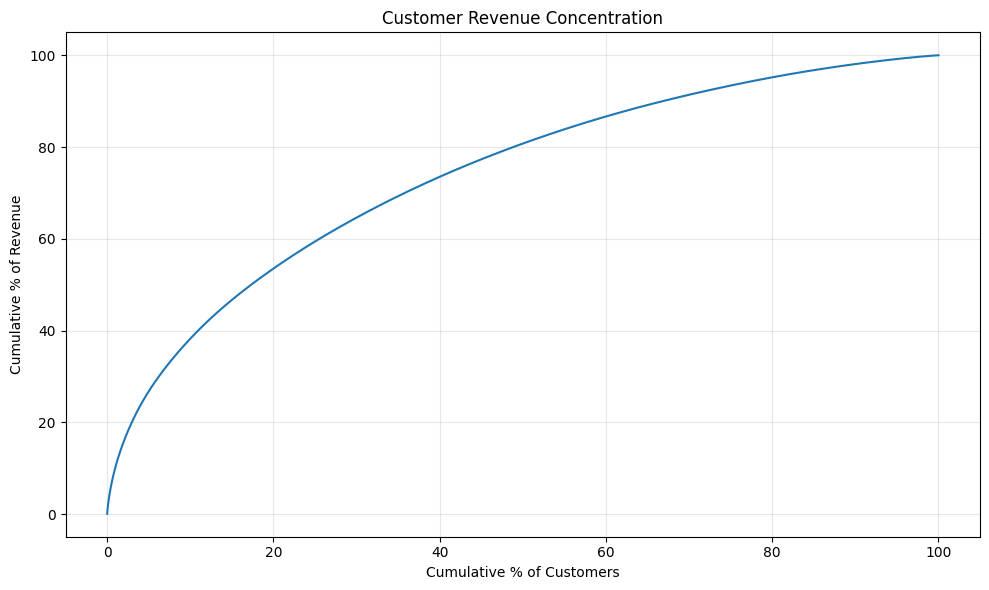

In [148]:
customer_revenue = (
    rfm["total_spend"]
    .sort_values(ascending=False)
    .reset_index(drop=True)
)

cumulative_revenue_share = (
    customer_revenue.cumsum()
    / customer_revenue.sum()
    * 100
)

customer_percentile = (
    (customer_revenue.index + 1)
    / len(customer_revenue)
    * 100
)

plt.figure(figsize=(10, 6))

plt.plot(
    customer_percentile,
    cumulative_revenue_share
)

plt.title("Customer Revenue Concentration")
plt.xlabel("Cumulative % of Customers")
plt.ylabel("Cumulative % of Revenue")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

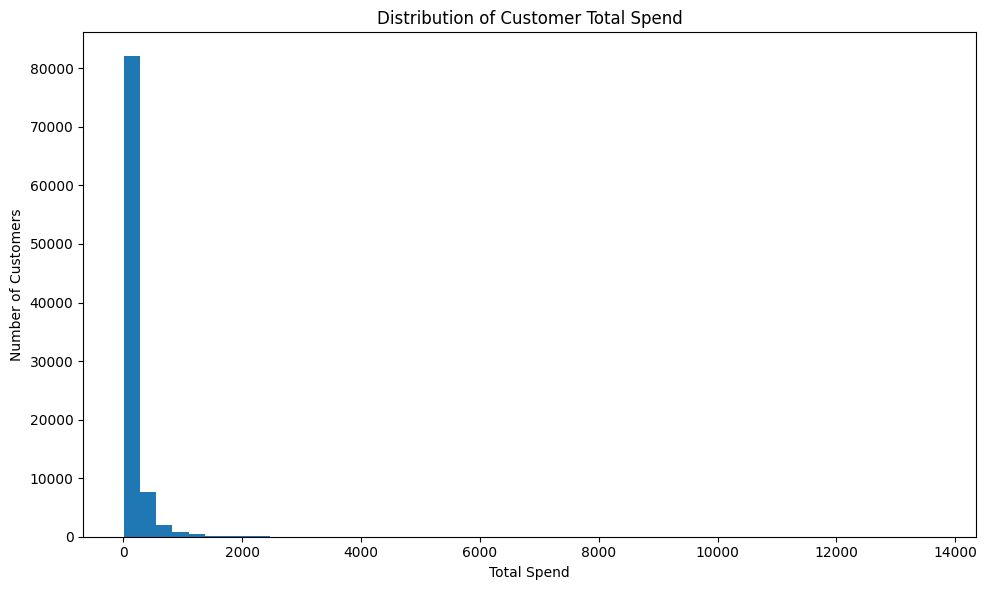

In [149]:
plt.figure(figsize=(10, 6))

plt.hist(
    rfm["total_spend"],
    bins=50
)

plt.title("Distribution of Customer Total Spend")
plt.xlabel("Total Spend")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [150]:
top_10_count = int(len(rfm) * 0.10)

top_10_revenue_share = (
    rfm["total_spend"]
    .sort_values(ascending=False)
    .head(top_10_count)
    .sum()
    / rfm["total_spend"].sum()
    * 100
)

top_10_revenue_share

np.float64(38.250985686479346)

In [151]:
top_20_count = int(len(rfm) * 0.20)

top_20_revenue_share = (
    rfm["total_spend"]
    .sort_values(ascending=False)
    .head(top_20_count)
    .sum()
    / rfm["total_spend"].sum()
    * 100
)

top_20_revenue_share

np.float64(53.52439798281736)

In [152]:
import os

for root, dirs, files in os.walk(".."):
    for file in files:
        if file in [
            "olist_products_dataset.csv",
            "product_category_name_translation.csv"
        ]:
            print(os.path.join(root, file))

..\02_data\raw\olist_products_dataset.csv
..\02_data\raw\product_category_name_translation.csv


In [153]:
products = pd.read_csv(
    "../02_data/raw/olist_products_dataset.csv"
)

category_translation = pd.read_csv(
    "../02_data/raw/product_category_name_translation.csv"
)

In [154]:
print("products:", products.shape)
print(products.columns.tolist())

print("\ncategory_translation:", category_translation.shape)
print(category_translation.columns.tolist())

products: (32951, 9)
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

category_translation: (71, 2)
['product_category_name', 'product_category_name_english']


In [155]:
customers.columns.tolist()

['customer_id',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state']

In [156]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
][
    ["order_id", "customer_id"]
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

In [157]:
delivered_orders.shape

(96478, 3)

In [158]:
delivered_orders[[
    "order_id",
    "customer_id",
    "customer_unique_id"
]].head()

,order_id,customer_id,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6


In [159]:
delivered_orders["customer_unique_id"].isna().sum()

np.int64(0)

In [160]:
product_sales = order_items.merge(
    delivered_orders,
    on="order_id",
    how="inner"
)

In [161]:
print("product_sales shape:", product_sales.shape)

product_sales shape: (110197, 10)


In [162]:
product_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,item_total_value,customer_id,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,72.19,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,259.83,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,216.87,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,25.78,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,218.04,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5


In [163]:
product_sales[
    [
        "order_id",
        "product_id",
        "price",
        "freight_value",
        "item_total_value",
        "customer_unique_id"
    ]
].head()

,order_id,product_id,price,freight_value,item_total_value,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,72.19,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,259.83,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,216.87,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.99,12.79,25.78,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,199.90,18.14,218.04,64b576fb70d441e8f1b2d7d446e483c5


In [164]:
product_sales["customer_unique_id"].isna().sum()

np.int64(0)

In [165]:
product_sales = product_sales.merge(
    products,
    on="product_id",
    how="left"
)

In [166]:
print("Shape:", product_sales.shape)

Shape: (110197, 18)


In [167]:
product_sales[
    [
        "product_id",
        "product_category_name",
        "price",
        "freight_value",
        "item_total_value"
    ]
].head()

,product_id,product_category_name,price,freight_value,item_total_value
0,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,13.29,72.19
1,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,19.93,259.83
2,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,199.00,17.87,216.87
3,7634da152a4610f1595efa32f14722fc,perfumaria,12.99,12.79,25.78
4,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,199.90,18.14,218.04


In [168]:
print(
    "Missing product matches:",
    product_sales["product_category_name"].isna().sum()
)

Missing product matches: 1537


In [169]:
product_sales["product_id"].nunique()

32216

In [170]:
product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

In [171]:
print("Shape:", product_sales.shape)

Shape: (110197, 19)


In [172]:
print(
    "Missing English categories:",
    product_sales["product_category_name_english"].isna().sum()
)

Missing English categories: 1559


In [173]:
product_sales[
    [
        "product_id",
        "product_category_name",
        "product_category_name_english",
        "price",
        "freight_value",
        "item_total_value"
    ]
].head(10)

,product_id,product_category_name,product_category_name_english,price,freight_value,item_total_value
0,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,cool_stuff,58.90,13.29,72.19
1,e5f2d52b802189ee658865ca93d83a8f,pet_shop,pet_shop,239.90,19.93,259.83
2,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,furniture_decor,199.00,17.87,216.87
3,7634da152a4610f1595efa32f14722fc,perfumaria,perfumery,12.99,12.79,25.78
4,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,garden_tools,199.90,18.14,218.04
5,ef92defde845ab8450f9d70c526ef70f,utilidades_domesticas,housewares,21.90,12.69,34.59
6,8d4f2bb7e93e6710a28f34fa83ee7d28,telefonia,telephony,19.90,11.85,31.75
7,557d850972a7d6f792fd18ae1400d9b6,ferramentas_jardim,garden_tools,810.00,70.75,880.75
8,310ae3c140ff94b03219ad0adc3c778f,beleza_saude,health_beauty,145.95,11.65,157.60
9,4535b0e1091c278dfd193e5a1d63b39f,livros_tecnicos,books_technical,53.99,11.40,65.39


In [174]:
product_sales["category"] = (
    product_sales["product_category_name_english"]
    .fillna("unknown")
)

In [175]:
product_sales["category"].isna().sum()

np.int64(0)

In [176]:
product_sales["category"].value_counts().head(15)

category
bed_bath_table           10953
health_beauty             9465
sports_leisure            8431
furniture_decor           8160
computers_accessories     7644
housewares                6795
watches_gifts             5859
telephony                 4430
garden_tools              4268
auto                      4140
toys                      4030
cool_stuff                3718
perfumery                 3340
baby                      2982
electronics               2729
Name: count, dtype: int64

In [177]:
category_performance = (
    product_sales
    .groupby("category")
    .agg(
        revenue=("price", "sum"),
        freight_value=("freight_value", "sum"),
        transaction_value=("item_total_value", "sum"),
        units_sold=("order_item_id", "count"),
        orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique"),
        avg_item_price=("price", "mean")
    )
    .reset_index()
)

In [178]:
category_performance.head()

,category,revenue,freight_value,transaction_value,units_sold,orders,unique_products,avg_item_price
0,agro_industry_and_commerce,70566.10,5637.20,76203.30,206,177,71,342.553883
1,air_conditioning,53323.56,6530.99,59854.55,289,246,121,184.510588
2,art,23657.30,3828.23,27485.53,197,195,52,120.087817
3,arts_and_craftmanship,1814.01,370.13,2184.14,24,23,19,75.583750
4,audio,50570.60,5684.72,56255.32,362,348,58,139.697790


In [179]:
category_performance["revenue_share"] = (
    category_performance["revenue"]
    / category_performance["revenue"].sum()
    * 100
)

In [180]:
category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
)

In [181]:
category_performance.head(15)

,category,revenue,freight_value,transaction_value,units_sold,orders,unique_products,avg_item_price,revenue_share
43,health_beauty,1233131.72,178957.81,1412089.53,9465,8647,2397,130.283330,9.326717
71,watches_gifts,1166176.98,98156.14,1264333.12,5859,5495,1300,199.040276,8.820309
7,bed_bath_table,1023434.76,201774.50,1225209.26,10953,9272,2991,93.438762,7.740687
65,sports_leisure,954852.55,163404.36,1118256.91,8431,7530,2822,113.254958,7.221969
15,computers_accessories,888724.61,143999.16,1032723.77,7644,6530,1600,116.264339,6.721815
39,furniture_decor,711927.69,168402.23,880329.92,8160,6307,2593,87.246040,5.384622
49,housewares,615628.69,142763.56,758392.25,6795,5743,2282,90.600249,4.656270
20,cool_stuff,610204.10,81476.79,691680.89,3718,3559,770,164.121598,4.615242
5,auto,578966.65,90488.10,669454.75,4140,3810,1853,139.847017,4.378979
69,toys,471286.48,75774.58,547061.06,4030,3804,1373,116.944536,3.564547
